Start by importing packages and fire dataset, then subset to 2025. 

In [32]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris

In [2]:
# import dataset
# parents.[1] suggested by copilot ai 
# to direct project folder to top of directory
project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in CSV
fire_perims = pd.read_csv(raw_fldr / 'California_Historic_Fire_Perimeters_4486510518992991706.csv')

# convert alarm date, containment date to datetime objects
# want year to not include a day/month so will convert to string for now
fire_perims["Year"] = fire_perims["Year"].astype("Int64")

# alarm date and containment date have date/time included
fire_perims["Alarm Date"] = pd.to_datetime(fire_perims["Alarm Date"], format="%m/%d/%Y %I:%M:%S %p")
fire_perims["Containment Date"] = pd.to_datetime(fire_perims["Containment Date"], format="%m/%d/%Y %I:%M:%S %p")
fire_perims.info()

# report number of rows and columns 
fire_perims.shape


<class 'pandas.DataFrame'>
RangeIndex: 11139 entries, 0 to 11138
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   OBJECTID                      11139 non-null  int64         
 1   Year                          11068 non-null  Int64         
 2   State                         11139 non-null  str           
 3   Agency                        11091 non-null  str           
 4   Unit ID                       11086 non-null  str           
 5   Fire Name                     8363 non-null   str           
 6   Local Incident Number         10366 non-null  str           
 7   IRWIN ID                      1882 non-null   str           
 8   Alarm Date                    8566 non-null   datetime64[us]
 9   Containment Date              5543 non-null   datetime64[us]
 10  Cause                         11139 non-null  str           
 11  Collection Method             11139 non

(11139, 22)

In [ ]:
fire_perims.head()


False


In [3]:
# subset to 2025
fire_perims_25 = fire_perims[fire_perims['Year'] == 2025]
fire_perims_25.head()

# see if there are na values
print(fire_perims_25.isna().sum())

print(fire_perims_25.isna().mean().sort_values(ascending=False) * 100)

# note there is one fire without a containment date, but we will still keep it in the dataset
# drop some columns that are not needed for analysis and have missing data
fire_perims_25 = fire_perims_25.drop(columns=['OBJECTID', 'Unit ID', 'Local Incident Number', 'IRWIN ID', 'Comments', 'GlobalID',
'Fire Number (historical use)','Complex ID', 'Complex Name'])

OBJECTID                          0
Year                              0
State                             0
Agency                            0
Unit ID                           0
Fire Name                         0
Local Incident Number             0
IRWIN ID                          0
Alarm Date                        0
Containment Date                  1
Cause                             0
Collection Method                 0
Management Objective              0
GIS Calculated Acres              0
Comments                        197
Complex Name                    231
Complex ID                      231
Fire Number (historical use)    243
GlobalID                          0
Decade                            0
Shape__Area                       0
Shape__Length                     0
dtype: int64
Fire Number (historical use)    100.000000
Complex ID                       95.061728
Complex Name                     95.061728
Comments                         81.069959
Containment Date       

Learn about the dataset
- Rows/columns
- Column titles
- NA data
- Column statistics

In [4]:
# percent of missing data for each column after removing columns
fire_perims_25.isna().mean().sort_values(ascending=False) * 100


# add a column for month of alarm date
fire_perims_25['Alarm Month'] = fire_perims_25['Alarm Date'].dt.month

fire_perims_25['Alarm Month Abb'] = pd.Categorical(
    values = fire_perims_25['Alarm Date'].dt.month_name().str[:3],
    categories=calendar.month_abbr[1:]
)
fire_perims_25.head()

,Year,State,Agency,Fire Name,Alarm Date,Containment Date,Cause,Collection Method,Management Objective,GIS Calculated Acres,Decade,Shape__Area,Shape__Length,Alarm Month,Alarm Month Abb
2,2025,California,California Department of Forestry and Fire Pro...,GRANGE,2025-05-18,2025-05-18,Miscellaneous,1 - GPS Ground,Suppression (Wildfire),19.91957,2020-2025,1.288790e+05,1586.431281,5,May
37,2025,California,California Department of Forestry and Fire Pro...,IVERSON,2025-06-19,2025-06-19,Miscellaneous,1 - GPS Ground,Suppression (Wildfire),10.73471,2020-2025,6.744486e+04,1314.291669,6,Jun
62,2025,California,California Department of Forestry and Fire Pro...,RICA,2025-06-13,2025-06-13,Equipment Use,1 - GPS Ground,Suppression (Wildfire),24.32036,2020-2025,1.644806e+05,2022.371292,6,Jun
86,2025,California,California Department of Forestry and Fire Pro...,STONEWALL,2025-08-31,2025-08-31,Arson,7 - Mixed Collection Methods,Suppression (Wildfire),31.06484,2020-2025,1.947749e+05,2252.738934,8,Aug
107,2025,California,California Department of Forestry and Fire Pro...,COYOTE,2025-08-20,2025-08-24,Arson,3 - Infrared,Suppression (Wildfire),623.90640,2020-2025,4.132354e+06,13651.255866,8,Aug


Answer some basic questions about the fire dataset: 
- How are the 2025 fires distributed temporally? 
- How are the 2025 fires distributed spatially? 
- What are the sizes of the 2025 fires? 

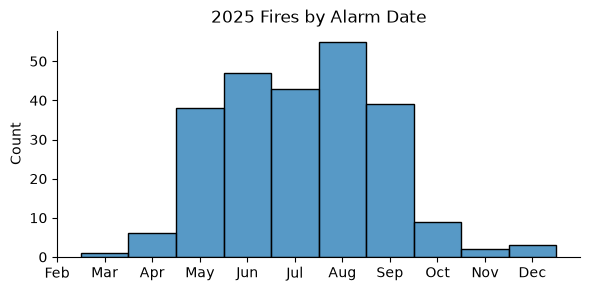

In [5]:
# Plot number of fires by month

g = sns.displot(
    data = fire_perims_25,
    x = 'Alarm Month Abb',
    height=3,
    aspect=2
)

g.set(
    title = "2025 Fires by Alarm Date",
    xlabel="",
    ylabel="Count"
);



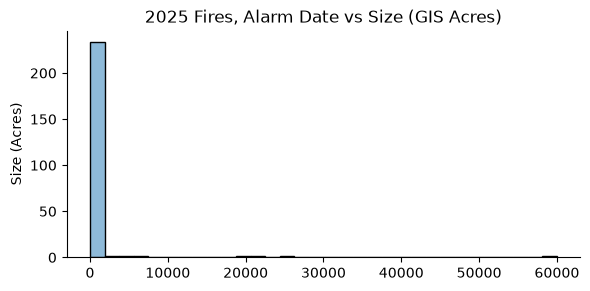

In [6]:
# Size distribution figure
g = sns.displot(
    data = fire_perims_25,
    x = 'GIS Calculated Acres',
    kind='hist',
    height=3,
    aspect=2,
    alpha=0.5
)

g.set(
    title = "2025 Fires, Alarm Date vs Size (GIS Acres)",
    xlabel="",
    ylabel="Size (Acres)"
);



In [ ]:
# Now we need to look at the fire perimeter shapefile 
# Also needs to be accessed through Box, and shapefile is inside .gdb
# fire perimeter layer name firep25_1

# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
# uploading wetlands that are bigger than a hectare
fire_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'fire25_1.gdb'
print(fire_path.exists())

fire_shp = gpd.read_file(fire_path, layer='firep25_1')



Box folder found at /Users/katanderson/Library/CloudStorage/Box-Box
True


/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined. Further messages of this type will be suppressed.
  return ogr_read(
/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts.  The processing may be really slow.  You can skip the processing by setting METHOD=SKIP. Further messages of this type will be suppressed.
  return ogr_read(


In [ ]:
# inspect shapefile data - similar columns but less information than the CSV file
# But we can join them

# look at columns, data types, counts
fire_shp.info()
fire_shp.head()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 23334 entries, 0 to 23333
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   YEAR_         23257 non-null  float64            
 1   STATE         23334 non-null  str                
 2   AGENCY        23286 non-null  str                
 3   UNIT_ID       23274 non-null  str                
 4   FIRE_NAME     16751 non-null  str                
 5   INC_NUM       22379 non-null  str                
 6   IRWINID       3634 non-null   str                
 7   ALARM_DATE    17950 non-null  datetime64[ms, UTC]
 8   CONT_DATE     10716 non-null  datetime64[ms, UTC]
 9   C_METHOD      23334 non-null  int16              
 10  CAUSE         23334 non-null  int16              
 11  OBJECTIVE     23063 non-null  float64            
 12  GIS_ACRES     23334 non-null  float32            
 13  COMPLEX_ID    585 non-null    str                
 14

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,OBJECTIVE,GIS_ACRES,COMPLEX_ID,COMPLEX_NAME,COMMENTS,FIRE_NUM,Shape_Length,Shape_Area,GlobalID,geometry
0,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01 00:00:00+00:00,2025-10-14 00:00:00+00:00,3,...,1.0,131613.531250,NaN,NaN,NaN,NaN,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},"MULTIPOLYGON (((-35131.146 -302750.005, -35107..."
1,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02 00:00:00+00:00,2025-07-26 00:00:00+00:00,7,...,1.0,80779.101562,NaN,NaN,NaN,NaN,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},"MULTIPOLYGON (((-4405.284 -313794.721, -4405.4..."
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24 00:00:00+00:00,2025-10-23 00:00:00+00:00,3,...,1.0,60019.234375,NaN,NaN,NaN,NaN,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},"MULTIPOLYGON (((89617.826 -122364.58, 89614.97..."
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02 00:00:00+00:00,2025-09-17 00:00:00+00:00,7,...,1.0,25553.546875,NaN,NaN,Park incident clipped out per BEU,NaN,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},"MULTIPOLYGON (((-31970.799 -229822.278, -31947..."
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,...,1.0,23448.882812,NaN,NaN,NaN,NaN,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},"MULTIPOLYGON (((136696.228 -441776.379, 136683..."


In [26]:
# look at na values
print(fire_shp.isna().sum())

# subset to 2025
fire_shp_25 = fire_shp[fire_shp['YEAR_'] == 2025]

YEAR_              77
STATE               0
AGENCY             48
UNIT_ID            60
FIRE_NAME        6583
INC_NUM           955
IRWINID         19700
ALARM_DATE       5384
CONT_DATE       12618
C_METHOD            0
CAUSE               0
OBJECTIVE         271
GIS_ACRES           0
COMPLEX_ID      22749
COMPLEX_NAME    22716
COMMENTS        20372
FIRE_NUM         5694
Shape_Length        0
Shape_Area          0
GlobalID            0
geometry            0
dtype: int64


Next, I want to visualize the fire perimeter shapefile. I also want to include CA state boundaries, so I am using the pygris package to access US Census Bureau tiger/line shapefiles without downloading them. 
- to install pygris in environment, run %pip install pygris in a cell
- https://github.com/walkerke/pygris

Then I am using matplot and geopandas to make the map!

Using the default year of 2024


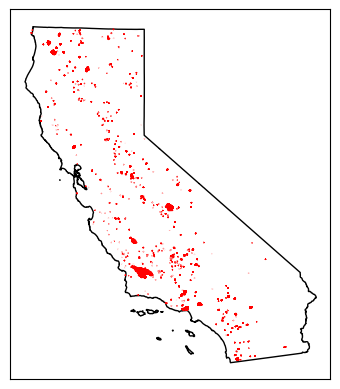

In [ ]:
# make a plot of 2025 fire perimeter shapefile
state_outlines = pygris.states()
state_outlines.head()
ca_outline = state_outlines[state_outlines['NAME'] == 'California']

# make sure CA and fire shapefile are in same CRS
ca_outline_proj= ca_outline.to_crs(fire_shp_25.crs)


# create the empty plot

fig, ax = plt.subplots()
# add the CA outline
ca_outline_proj.plot(ax=ax,color='white',edgecolor='black')
# add the fire perimeters
fire_shp_25.plot(ax=ax,figsize=(10,10), color='red', edgecolor='red')

# consult google gemini to learn how to turn axes off
ax.axis=('off')
ax.get_xaxis().set_visible(False) # Explicitly hide X elements
ax.get_yaxis().set_visible(False)